# LAPD Crimes — Visualizações dos clusters

**Projeto Integrador III — Ciência de Dados e Machine Learning, CEUB**

Terceiro e último notebook da cadeia:

`01 limpeza` → `data/processed/lapd_clean.csv` → `02 clusterização` → **`data/processed/amostra_clusters.csv`** → **`03 visualizações` (este notebook)**

Ele **só lê** o CSV exportado pela clusterização (e, se existirem, `metricas_escolha_k.csv` e `associacao_clusters.csv`). Não refaz nenhum agrupamento.

### Perguntas que as figuras respondem

| Seção | Pergunta |
|---|---|
| 2 | Qual o tamanho e o desfecho de cada cluster? |
| 3 | **O quê**: o que caracteriza cada cluster (crime, local, arma)? |
| 4 | **Quando**: período do dia, dia da semana e evolução mensal |
| 5 | **Quem**: sexo, idade e ascendência das vítimas |
| 6 | **Onde**: áreas do LAPD e mapa (se o CSV tiver `LAT`/`LON`) |
| 7 | Desfecho: taxa de prisão por cluster e por crime |
| 8 | Modus operandi (`CLUSTER_MO`) × clusters K-Modes |
| 9 | Evidência de que há (ou não) estrutura: métricas de escolha de k |

Convenção de leitura dos mapas de calor: **lift** = frequência da categoria no cluster ÷ frequência na base. Escala em log₂: vermelho = sobre-representada, azul = sub-representada, cinza = na média.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1. Configuração e carga

In [2]:
DIR_PROCESSADOS = "data/processed"
DIR_FIGURAS = "docs/figuras"
CAMINHO_CLUSTERS = f"{DIR_PROCESSADOS}/amostra_clusters.csv"
CAMINHO_METRICAS_K = f"{DIR_PROCESSADOS}/metricas_escolha_k.csv"
CAMINHO_ASSOC = f"{DIR_PROCESSADOS}/associacao_clusters.csv"

os.makedirs(DIR_FIGURAS, exist_ok=True)

# Estilo idêntico ao do notebook de clusterização
AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#b8302f"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 6,
})

def salvar(nome):
    plt.savefig(f"{DIR_FIGURAS}/{nome}.png", dpi=150, bbox_inches="tight")

In [3]:
if not os.path.exists(CAMINHO_CLUSTERS):
    raise FileNotFoundError(
        f"{CAMINHO_CLUSTERS} não existe. Rode antes o notebook de clusterização (seção 'Exportação').")

df = pd.read_csv(CAMINHO_CLUSTERS, dtype=str)

# Contrato com o notebook de clusterização: colunas que ele exporta
FEATS = ["CRIME", "LOCAL", "ARMA", "PERIODO", "DIA"]
DESCRITIVAS = ["AREA_NOME", "SEXO_VIT", "ASCEND_VIT", "FAIXA_IDADE", "PRISAO", "ANO"]
OBRIGATORIAS = ["DR_NO", "DATA_OCC"] + FEATS + DESCRITIVAS + ["CLUSTER", "CLUSTER_MO"]
faltando = [c for c in OBRIGATORIAS if c not in df.columns]
assert not faltando, f"Colunas ausentes no CSV de clusters: {faltando}"

df["DATA_OCC"] = pd.to_datetime(df["DATA_OCC"], errors="coerce")
df["CLUSTER"] = df["CLUSTER"].astype(int)
K = df["CLUSTER"].nunique()
CLUSTERS = sorted(df["CLUSTER"].unique())

# Coordenadas são opcionais: só existem se o notebook de clusterização as exportar
TEM_GEO = {"LAT", "LON"} <= set(df.columns)
if TEM_GEO:
    df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
    df["LON"] = pd.to_numeric(df["LON"], errors="coerce")

df["DIA_SEMANA"] = df["DATA_OCC"].dt.day_name()
df["MES"] = df["DATA_OCC"].dt.to_period("M").dt.to_timestamp()

print(f"{len(df):,} registros · {K} clusters · período {df['DATA_OCC'].min():%Y-%m-%d} a {df['DATA_OCC'].max():%Y-%m-%d}")
print("Coordenadas disponíveis:", TEM_GEO)
df[["DR_NO", "DATA_OCC", "CLUSTER", "CLUSTER_MO"] + FEATS].head()

50,000 registros · 6 clusters · período 2020-01-01 a 2024-02-29
Coordenadas disponíveis: True


,DR_NO,DATA_OCC,CLUSTER,CLUSTER_MO,CRIME,LOCAL,ARMA,PERIODO,DIA
0,221116036,2022-11-07,2,MO_5,BATTERY - SIMPLE ASSAULT,PARKING LOT,FORCA_FISICA,TARDE,DIA_UTIL
1,221408002,2022-03-21,0,MO_8,BURGLARY FROM VEHICLE,STREET,SEM_ARMA,MANHA,DIA_UTIL
2,201917904,2020-11-17,5,MO_7,THEFT PLAIN - PETTY ($950 & UNDER),OUTROS,SEM_ARMA,MANHA,DIA_UTIL
3,231419177,2023-10-19,5,MO_0,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",OUTROS,OUTRA/DESCONHECIDA,TARDE,DIA_UTIL
4,230600758,2023-07-01,0,MO_7,OUTROS,STREET,SEM_ARMA,NOITE,FIM_DE_SEMANA


### Funções de apoio

`tabela_lift`, `heatmap_lift` e `cramers_v` são as mesmas do notebook de clusterização (com um parâmetro a mais, `ordem`, para fixar a ordem das colunas em variáveis ordinais como período e dia da semana).

In [4]:
def tabela_lift(dados, col, grupo="CLUSTER"):
    p_c = dados[col].value_counts(normalize=True)
    p_cg = pd.crosstab(dados[grupo], dados[col], normalize="index")
    return p_cg / p_c

def heatmap_lift(dados, col, top=None, ordem=None, titulo=None, nome=None, grupo="CLUSTER"):
    l = tabela_lift(dados, col, grupo)
    if ordem:
        l = l[[c for c in ordem if c in l.columns]]
    elif top:
        l = l[dados[col].value_counts().index[:top]]
    l2 = np.log2(l.clip(lower=1 / 8)).clip(-3, 3)
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * l2.shape[1] + 2), 0.5 * l2.shape[0] + 2))
    sns.heatmap(l2, cmap=DIV, center=0, vmin=-3, vmax=3, linewidths=2, linecolor="#fcfcfb",
                annot=l.round(1), fmt="", annot_kws={"fontsize": 7}, cbar_kws={"label": "log₂(lift)"}, ax=ax)
    ax.set_title(titulo or f"{col} por {grupo} (lift)")
    ax.set_xlabel(""); ax.grid(False)
    plt.xticks(rotation=60, ha="right")
    if nome: salvar(nome)
    plt.show()

def cramers_v(x, y):
    # V de Cramér com correção de viés (Bergsma, 2013)
    tab = pd.crosstab(x, y)
    if min(tab.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return np.sqrt(phi2 / den) if den > 0 else np.nan

## 2. Visão geral dos clusters

Tamanho, taxa de prisão e o tipo de crime mais sobre-representado em cada cluster (lift, exigindo ao menos 5% do cluster para não destacar categorias raras).

In [5]:
def crime_destaque(g, suporte_min=0.05):
    sub = df[df.CLUSTER == g]
    p = sub["CRIME"].value_counts(normalize=True)
    l = tabela_lift(df, "CRIME").loc[g]
    cand = l[p.reindex(l.index).fillna(0) >= suporte_min].drop("OUTROS", errors="ignore")
    if cand.empty:
        return "—"
    v = cand.idxmax()
    return f"{v} ({cand[v]:.1f}×)"

resumo = pd.DataFrame({
    "n": df["CLUSTER"].value_counts().sort_index(),
})
resumo["%"] = (resumo["n"] / len(df) * 100).round(1)
resumo["taxa_prisao_%"] = df.groupby("CLUSTER")["PRISAO"].apply(lambda s: (s == "PRISAO").mean() * 100).round(1)
resumo["crime_mais_sobre-representado"] = [crime_destaque(g) for g in resumo.index]
resumo.index.name = "CLUSTER"
with pd.option_context("display.max_colwidth", None):
    display(resumo)

,n,%,taxa_prisao_%,crime_mais_sobre-representado
CLUSTER,,,,
0,13039,26.1,8.0,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER) (1.6×)
1,8898,17.8,16.6,INTIMATE PARTNER - SIMPLE ASSAULT (5.1×)
2,2565,5.1,12.0,BATTERY - SIMPLE ASSAULT (6.5×)
3,11830,23.7,7.0,VEHICLE - STOLEN (2.5×)
4,6694,13.4,7.9,BURGLARY (4.6×)
5,6974,13.9,8.3,SHOPLIFTING - PETTY THEFT ($950 & UNDER) (3.4×)


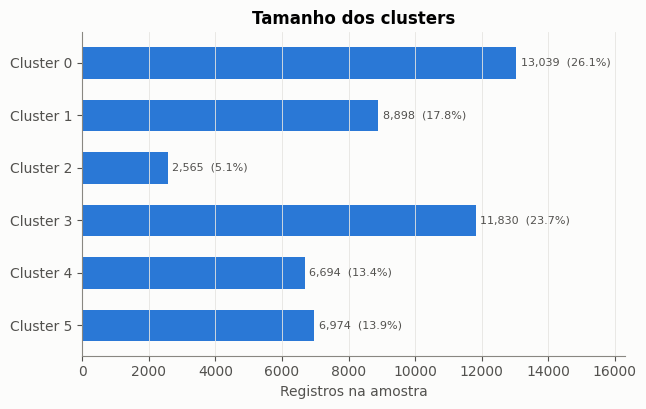

In [6]:
tam = df["CLUSTER"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 0.45 * K + 1.5))
ax.barh([f"Cluster {g}" for g in tam.index][::-1], tam.values[::-1], color=AZUL, height=0.6)
for y, v in enumerate(tam.values[::-1]):
    ax.text(v + tam.max() * 0.01, y, f"{v:,}  ({v / len(df):.1%})", va="center", color=TINTA2, fontsize=8)
ax.set_xlim(0, tam.max() * 1.25)
ax.set_xlabel("Registros na amostra")
ax.set_title("Tamanho dos clusters")
ax.grid(axis="y", visible=False)
salvar("20_tamanho_clusters")
plt.show()

## 3. O quê: crime, local e arma por cluster

Estas são as variáveis que **formaram** o agrupamento. O mapa de calor mostra o que distingue cada cluster do restante da base.

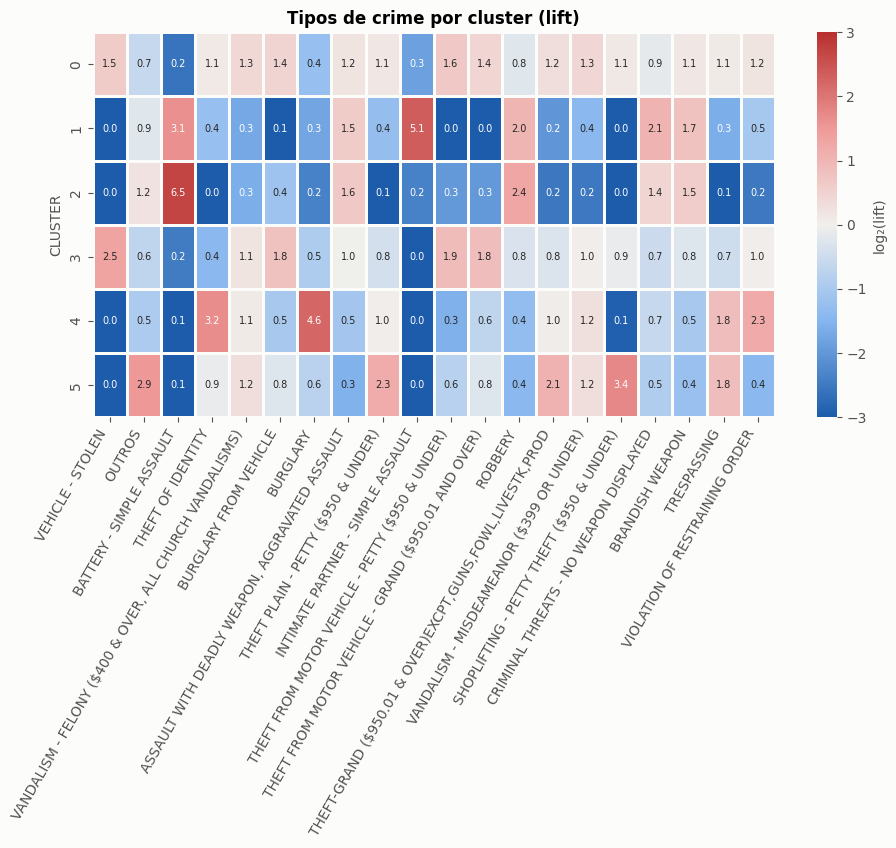

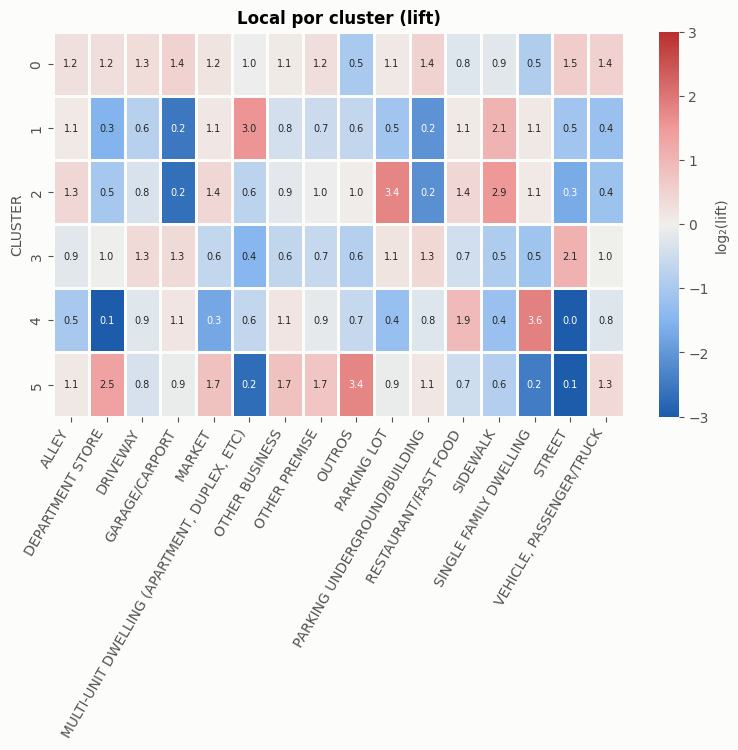

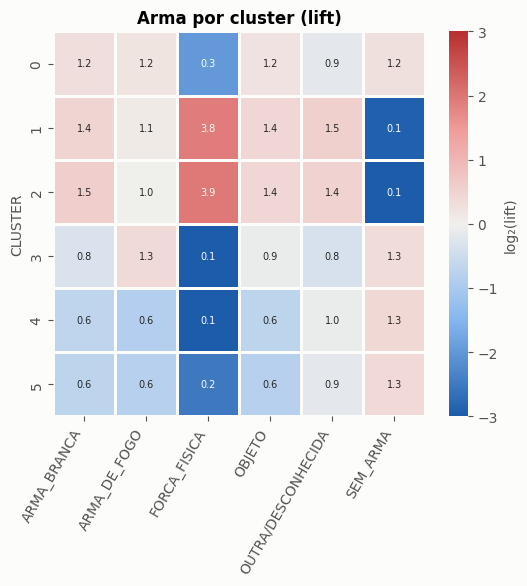

In [7]:
heatmap_lift(df, "CRIME", top=20, titulo="Tipos de crime por cluster (lift)", nome="21_lift_crime")
heatmap_lift(df, "LOCAL", titulo="Local por cluster (lift)", nome="22_lift_local")
heatmap_lift(df, "ARMA", titulo="Arma por cluster (lift)", nome="23_lift_arma")

## 4. Quando: período, dia da semana e evolução mensal

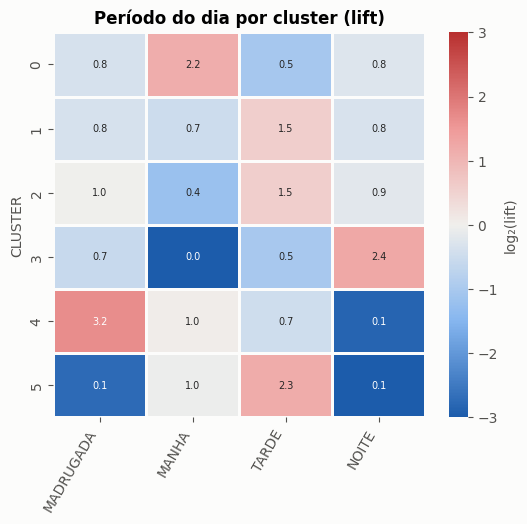

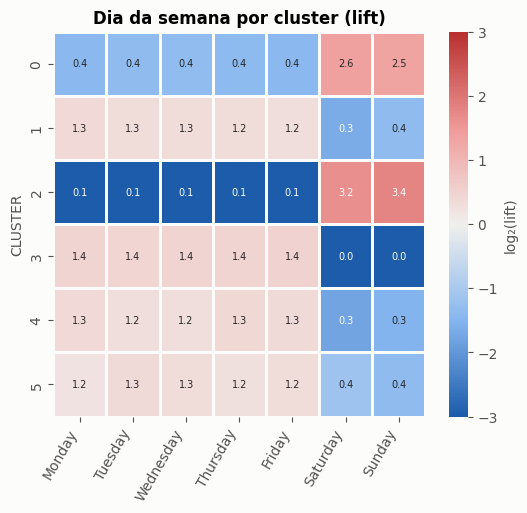

In [8]:
ORDEM_PERIODO = ["MADRUGADA", "MANHA", "TARDE", "NOITE", "SEM_HORA"]
ORDEM_SEMANA = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heatmap_lift(df, "PERIODO", ordem=ORDEM_PERIODO, titulo="Período do dia por cluster (lift)", nome="24_lift_periodo")
heatmap_lift(df, "DIA_SEMANA", ordem=ORDEM_SEMANA, titulo="Dia da semana por cluster (lift)", nome="25_lift_dia_semana")

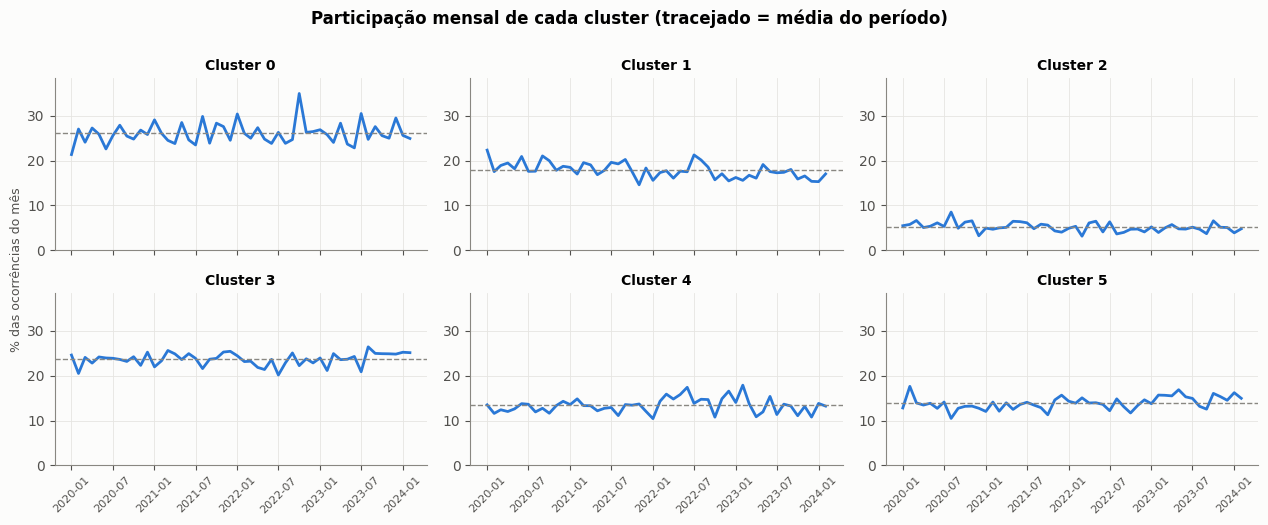

In [9]:
# Participação mensal de cada cluster (% das ocorrências do mês), com a participação média como referência
mensal = pd.crosstab(df["MES"], df["CLUSTER"], normalize="index") * 100
media = df["CLUSTER"].value_counts(normalize=True).sort_index() * 100

ncols = min(3, K)
nrows = int(np.ceil(K / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 2.6 * nrows), sharex=True, squeeze=False)
for ax, g in zip(axes.ravel(), CLUSTERS):
    ax.plot(mensal.index, mensal[g], color=AZUL)
    ax.axhline(media[g], color=CINZA, linestyle="--", linewidth=1)
    ax.set_title(f"Cluster {g}", fontsize=10)
    ax.set_ylim(0, max(mensal.max().max() * 1.1, 1))
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
for ax in axes.ravel()[K:]:
    ax.axis("off")
fig.supylabel("% das ocorrências do mês", color=TINTA2, fontsize=9)
fig.suptitle("Participação mensal de cada cluster (tracejado = média do período)", fontweight="bold", y=1.0)
plt.tight_layout()
salvar("26_participacao_mensal")
plt.show()

## 5. Quem: perfil da vítima

Sexo, idade e ascendência **não** entraram no agrupamento; o que aparece aqui é associação real entre o perfil do fato criminal e o perfil da vítima. O gráfico de barras compara a força da associação (V de Cramér) entre o rótulo de cluster e cada variável descritiva.

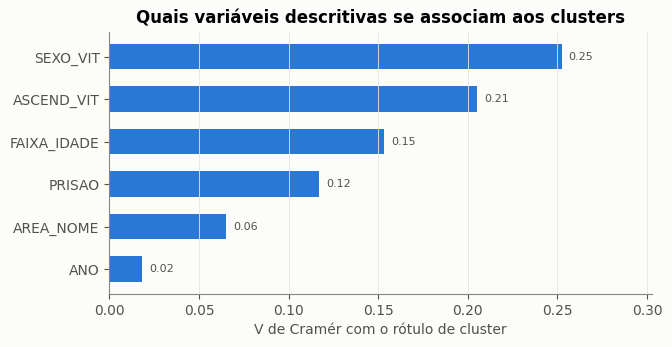

In [10]:
if os.path.exists(CAMINHO_ASSOC):
    assoc = pd.read_csv(CAMINHO_ASSOC, index_col=0)["V_cramer"]
else:
    assoc = pd.Series({c: cramers_v(df["CLUSTER"], df[c]) for c in DESCRITIVAS})
assoc = assoc.sort_values()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(assoc.index, assoc.values, color=AZUL, height=0.6)
for y, v in enumerate(assoc.values):
    ax.text(v + 0.004, y, f"{v:.2f}", va="center", color=TINTA2, fontsize=8)
ax.set_xlim(0, max(assoc.max() * 1.2, 0.1))
ax.set_xlabel("V de Cramér com o rótulo de cluster")
ax.set_title("Quais variáveis descritivas se associam aos clusters")
ax.grid(axis="y", visible=False)
salvar("27_associacao_cramer")
plt.show()

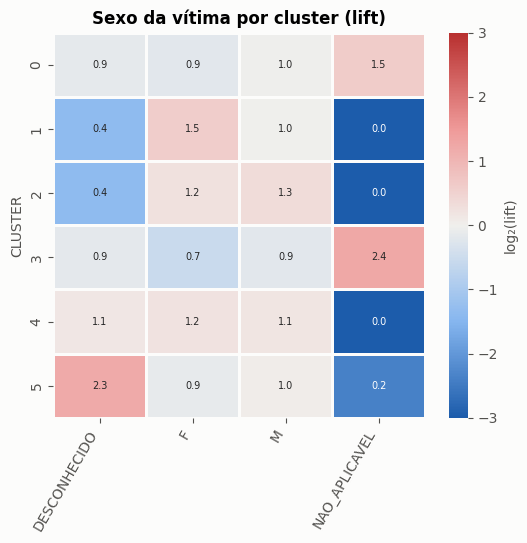

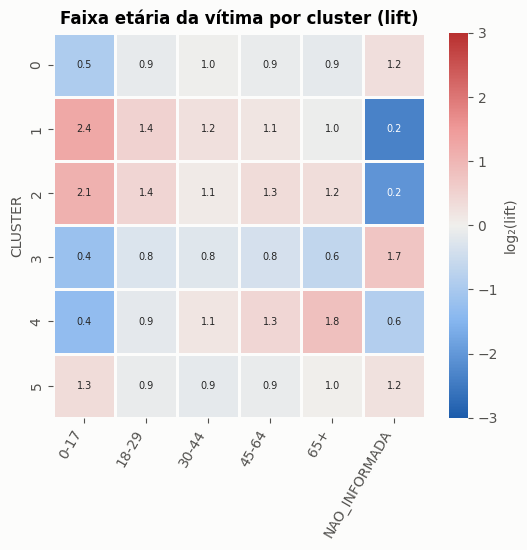

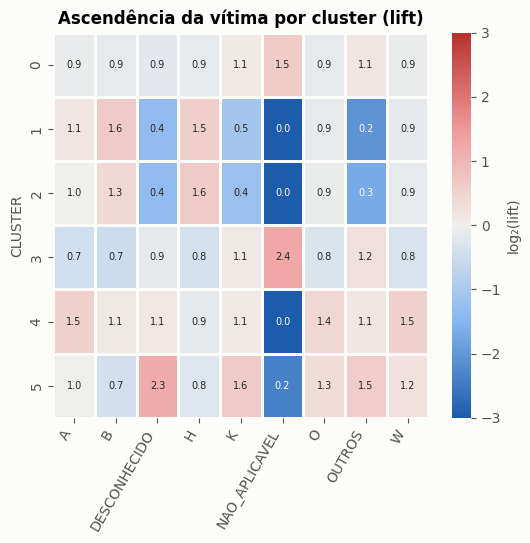

In [11]:
ORDEM_IDADE = ["0-17", "18-29", "30-44", "45-64", "65+", "NAO_INFORMADA"]
heatmap_lift(df, "SEXO_VIT", titulo="Sexo da vítima por cluster (lift)", nome="28_lift_sexo")
heatmap_lift(df, "FAIXA_IDADE", ordem=ORDEM_IDADE, titulo="Faixa etária da vítima por cluster (lift)", nome="29_lift_idade")
heatmap_lift(df, "ASCEND_VIT", titulo="Ascendência da vítima por cluster (lift)", nome="30_lift_ascendencia")

## 6. Onde: áreas do LAPD e mapa

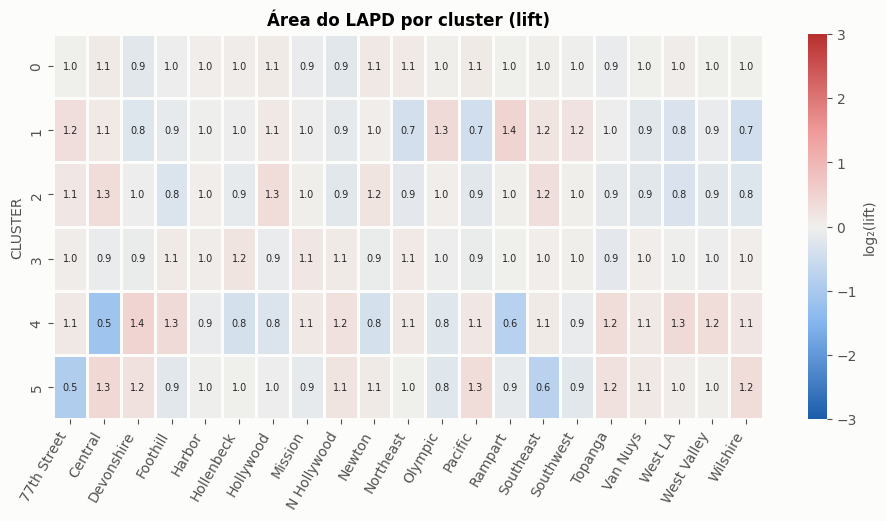

In [12]:
heatmap_lift(df, "AREA_NOME", titulo="Área do LAPD por cluster (lift)", nome="31_lift_area")

49,907 de 50,000 registros com coordenadas válidas


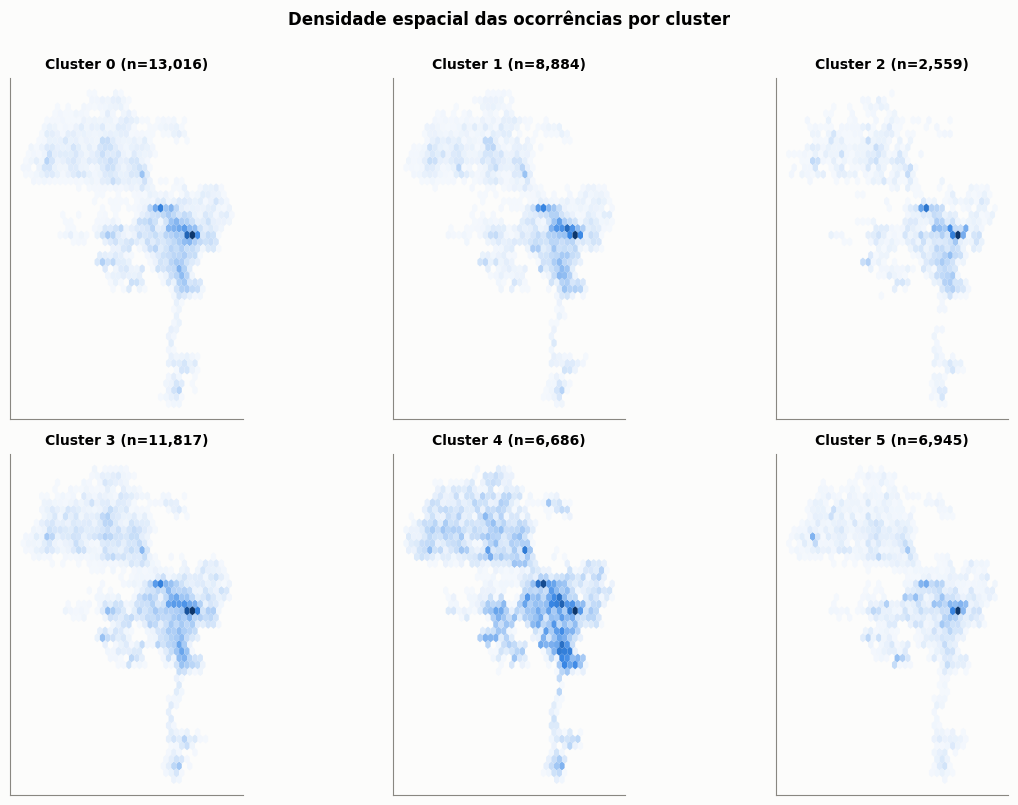

In [13]:
# Mapa de densidade por cluster. Requer LAT/LON no CSV de clusters.
if not TEM_GEO:
    print("O CSV de clusters não tem LAT/LON. Para habilitar o mapa, acrescente 'LAT' e 'LON' a "
          "`cols_saida` na Seção 10 do notebook 02 e rode-o de novo.")
else:
    # LAT/LON = 0 é sentinela de local desconhecido na base do LAPD
    geo = df[(df["LAT"] > 33) & (df["LAT"] < 35) & (df["LON"] > -119) & (df["LON"] < -117)]
    print(f"{len(geo):,} de {len(df):,} registros com coordenadas válidas")
    ncols = min(3, K)
    nrows = int(np.ceil(K / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows), sharex=True, sharey=True, squeeze=False)
    lim = (geo["LON"].min(), geo["LON"].max(), geo["LAT"].min(), geo["LAT"].max())
    for ax, g in zip(axes.ravel(), CLUSTERS):
        sub = geo[geo["CLUSTER"] == g]
        ax.hexbin(sub["LON"], sub["LAT"], gridsize=40, extent=lim, cmap=SEQ, mincnt=1, linewidths=0)
        ax.set_title(f"Cluster {g} (n={len(sub):,})", fontsize=10)
        ax.set_aspect(1 / np.cos(np.deg2rad(34)))
        ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for ax in axes.ravel()[K:]:
        ax.axis("off")
    fig.suptitle("Densidade espacial das ocorrências por cluster", fontweight="bold", y=1.0)
    plt.tight_layout()
    salvar("32_mapa_densidade")
    plt.show()

## 7. Desfecho: taxa de prisão

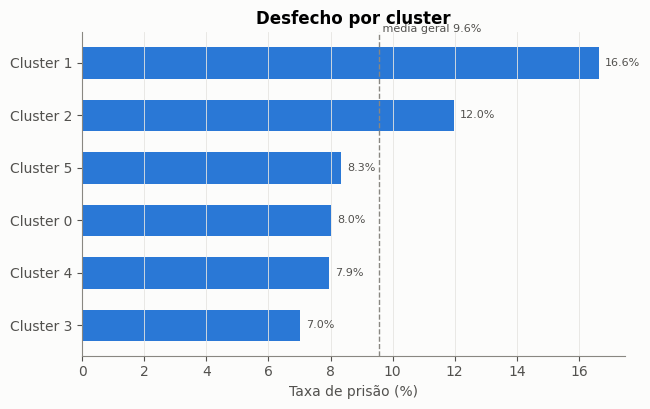

In [14]:
taxa = df.groupby("CLUSTER")["PRISAO"].apply(lambda s: (s == "PRISAO").mean() * 100).sort_values()
geral = (df["PRISAO"] == "PRISAO").mean() * 100
fig, ax = plt.subplots(figsize=(7, 0.45 * len(taxa) + 1.5))
ax.barh([f"Cluster {g}" for g in taxa.index], taxa.values, color=AZUL, height=0.6)
ax.axvline(geral, color=CINZA, linestyle="--", linewidth=1)
ax.text(geral, len(taxa) - 0.45, f" média geral {geral:.1f}%", color=TINTA2, fontsize=8, va="bottom")
for y, v in enumerate(taxa.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", color=TINTA2, fontsize=8)
ax.set_xlabel("Taxa de prisão (%)")
ax.set_title("Desfecho por cluster")
ax.grid(axis="y", visible=False)
salvar("33_prisao_cluster")
plt.show()

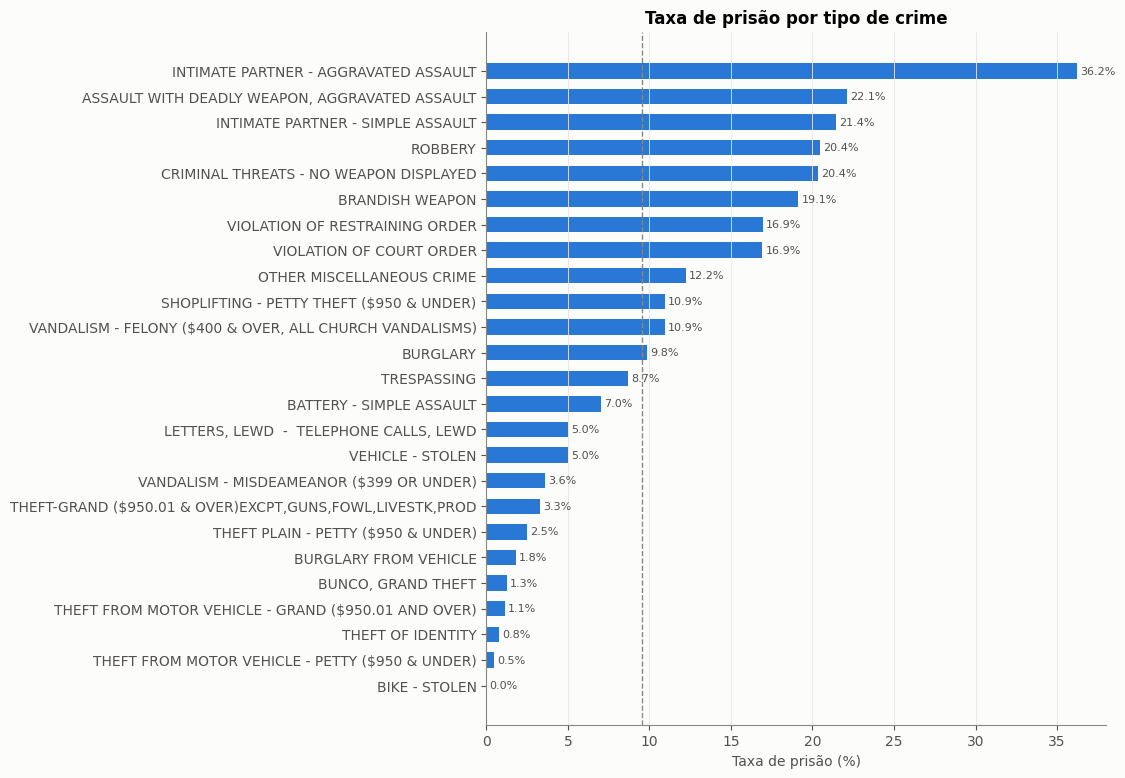

In [15]:
# Taxa de prisão por tipo de crime (categorias com pelo menos 200 registros)
t = df.groupby("CRIME")["PRISAO"].agg(n="size", taxa=lambda s: (s == "PRISAO").mean() * 100)
t = t[(t["n"] >= 200) & (t.index != "OUTROS")].sort_values("taxa")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(t) + 1.5))
ax.barh(t.index, t["taxa"], color=AZUL, height=0.6)
ax.axvline(geral, color=CINZA, linestyle="--", linewidth=1)
for y, v in enumerate(t["taxa"]):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", color=TINTA2, fontsize=8)
ax.set_xlabel("Taxa de prisão (%)")
ax.set_title("Taxa de prisão por tipo de crime")
ax.grid(axis="y", visible=False)
salvar("34_prisao_crime")
plt.show()

## 8. Modus operandi

`CLUSTER_MO` vem do agrupamento de `Mocodes` (TF-IDF → SVD → K-Means). Registros sem código de MO ficam em `SEM_MO` e são omitidos aqui. As linhas são os clusters K-Modes e as colunas, os clusters de MO.

Registros com MO: 86.3%


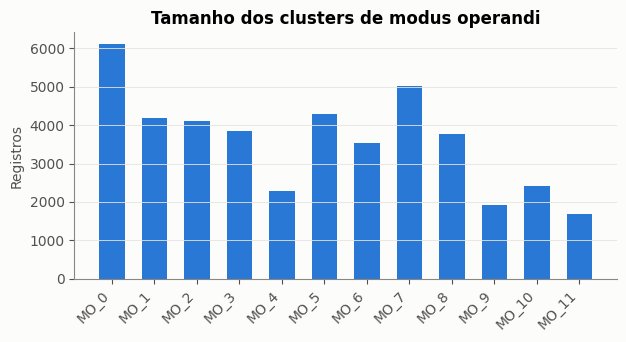

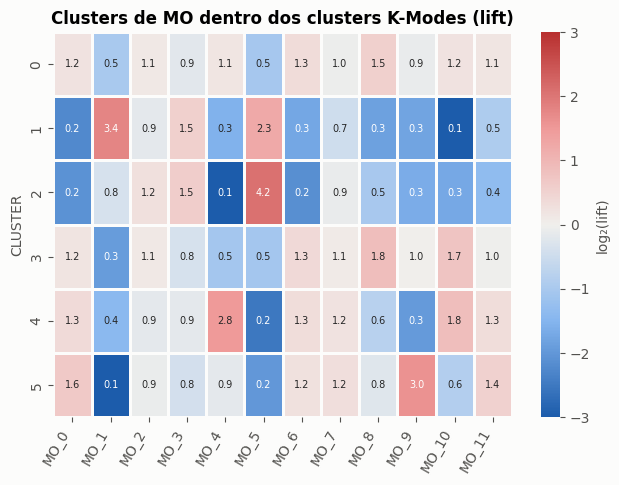

In [16]:
m = df["CLUSTER_MO"] != "SEM_MO"
print(f"Registros com MO: {m.mean():.1%}")

ordem_mo = sorted(df.loc[m, "CLUSTER_MO"].unique(), key=lambda s: int(s.split("_")[1]))
cont_mo = df.loc[m, "CLUSTER_MO"].value_counts().reindex(ordem_mo)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(cont_mo.index, cont_mo.values, color=AZUL, width=0.6)
ax.set_ylabel("Registros")
ax.set_title("Tamanho dos clusters de modus operandi")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=45, ha="right")
salvar("35_tamanho_mo")
plt.show()

heatmap_lift(df[m], "CLUSTER_MO", ordem=ordem_mo, titulo="Clusters de MO dentro dos clusters K-Modes (lift)", nome="36_lift_mo_kmodes")

## 9. Existe estrutura? Métricas de escolha de k

Reproduz o gráfico central do notebook de clusterização: se a redução de custo nos dados reais é muito próxima da obtida em dados embaralhados (modelo nulo) e a estabilidade (ARI) fica abaixo de ~0,6, os registros **não** formam grupos naturais nesse espaço de atributos. Isso é um resultado válido para o trabalho.

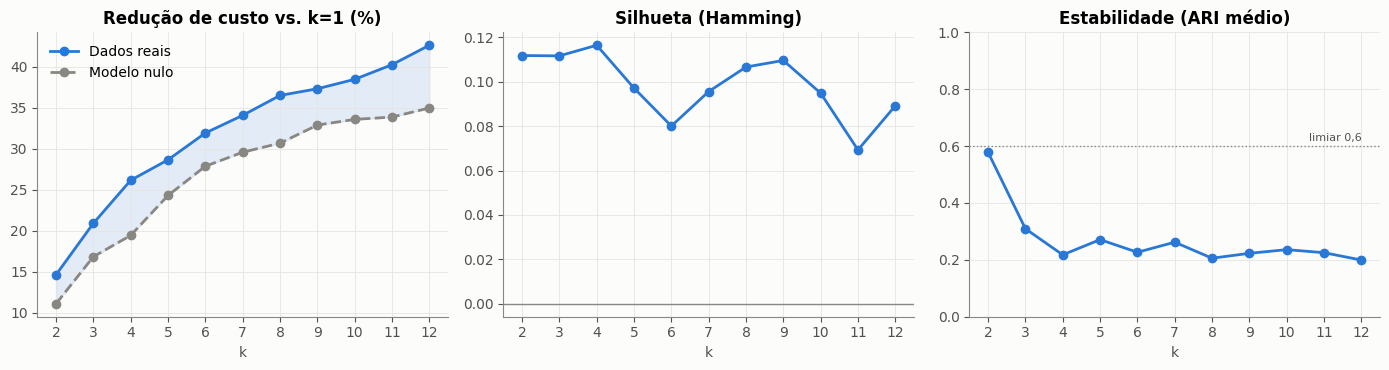

In [17]:
if not os.path.exists(CAMINHO_METRICAS_K):
    print(f"{CAMINHO_METRICAS_K} não encontrado; seção ignorada.")
else:
    res_k = pd.read_csv(CAMINHO_METRICAS_K, index_col="k")
    ks = res_k.index
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

    ax = axes[0]
    ax.plot(ks, res_k["reducao_real"] * 100, marker="o", color=AZUL, label="Dados reais")
    ax.plot(ks, res_k["reducao_nula"] * 100, marker="o", color=CINZA, linestyle="--", label="Modelo nulo")
    ax.fill_between(ks, res_k["reducao_nula"] * 100, res_k["reducao_real"] * 100, color=AZUL, alpha=0.12)
    ax.set_title("Redução de custo vs. k=1 (%)"); ax.set_xlabel("k"); ax.set_xticks(ks)
    ax.legend(frameon=False, loc="upper left")

    axes[1].plot(ks, res_k["silhueta"], marker="o", color=AZUL)
    axes[1].axhline(0, color=CINZA, linewidth=1)
    axes[1].set_title("Silhueta (Hamming)"); axes[1].set_xlabel("k"); axes[1].set_xticks(ks)

    axes[2].plot(ks, res_k["ari"], marker="o", color=AZUL)
    axes[2].axhline(0.6, color=CINZA, linestyle=":", linewidth=1)
    axes[2].text(ks[-1], 0.61, "limiar 0,6", ha="right", va="bottom", color=TINTA2, fontsize=8)
    axes[2].set_ylim(0, 1)
    axes[2].set_title("Estabilidade (ARI médio)"); axes[2].set_xlabel("k"); axes[2].set_xticks(ks)

    plt.tight_layout()
    salvar("37_metricas_k")
    plt.show()

## 10. Como ler (roteiro para o relatório)

1. **Tamanho e desfecho** (Seção 2) dão o panorama; clusters pequenos com taxa de prisão destoante merecem comentário.
2. **O quê, quando, quem, onde** (Seções 3–6): só descreva um cluster como "perfil" se o lift for claramente > 1,5× e a categoria tiver presença relevante dentro dele.
3. **Estrutura** (Seção 9): se silhueta ≈ 0 e ARI < 0,6, escreva que os clusters são **fatias descritivas** da base e não grupos naturais.
4. **Limitações**: as variáveis de vítima descrevem **vítimas**, não autores; os dados são **registros policiais**, não criminalidade; a amostra é aleatória de 50 mil registros, anteriores a 29/02/2024.